In [1]:
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'numpy'

In [2]:
%pip install numpy matplotlib

  Using cached matplotlib-3.11.2-cp313-cp313-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp313-cp313-macosx_10_13_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 29.3 MB/s eta 0:00:00a 0:00:01
Using cached matplotlib-3.11.2-cp313-cp313-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-macosx_11_0_arm64.whl (285 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp313-cp313-macosx_10_13_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp313-cp313-macosx_11_0_arm64.whl (64 kB)
Using cached

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def get_neighbors(cell: tuple[int, int], map: np.ndarray) -> list(tuple[int, int]):
    """ Gets a numpy array with all the adjacent cell indices """
    cell_idx = np.array(cell)
    neighbors = cell_idx[None,:]+np.array([[-1,0],[1,0],[0,-1],[0,1]])
    not_edge_of_map = (neighbors[:,0]>=0) & (neighbors[:,0]<map.shape[0]) & (neighbors[:,1]>=0) & (neighbors[:,1]<map.shape[1])
    neighbors = [tuple(n) for n in neighbors[not_edge_of_map]]
    return neighbors

[[6. 5. 4. 3. 3. 4. 5. 6. 7. 8.]
 [5. 4. 3. 2. 2. 3. 4. 5. 6. 7.]
 [4. 3. 2. 1. 1. 2. 3. 4. 5. 6.]
 [3. 2. 1. 0. 0. 1. 2. 3. 4. 5.]
 [3. 2. 1. 0. 1. 2. 3. 4. 4. 5.]
 [4. 3. 2. 1. 2. 3. 4. 4. 3. 4.]
 [5. 4. 3. 2. 3. 4. 4. 3. 2. 3.]
 [6. 5. 4. 3. 4. 4. 3. 2. 1. 2.]
 [7. 6. 5. 4. 4. 3. 2. 1. 0. 1.]
 [8. 7. 6. 5. 5. 4. 3. 2. 1. 2.]]


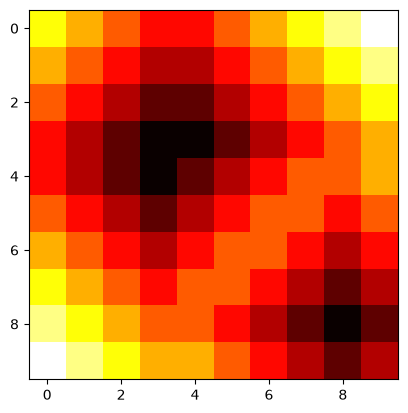

In [5]:
def lower_cells(map: np.ndarray, cells: list[tuple[int, int]], distance):
    """
    Updates cells with an decreasing distance from an obstacle.
    Used to insert an obstacle and update its neighbors.
    """
    # Initialize the original cells to the specified distance
    for cell in cells:
      map[cell[0], cell[1]] = distance

    open_list = cells.copy()
    closed_list = []
    while len(open_list) > 0:
      cell = open_list.pop(0)
      neighbors = get_neighbors(cell, map)
      neighbor_dist = map[cell[0],cell[1]] + 1
      for neighbor in neighbors:
        if neighbor in (closed_list+open_list):
          continue
        if map[neighbor[0], neighbor[1]] > neighbor_dist:
          map[neighbor[0], neighbor[1]] = neighbor_dist
          open_list.append(neighbor)
      closed_list.append(cell)

def add_obstacles(map: np.ndarray, cells: list[tuple[int, int]]) -> list[tuple[int,int]]:
    lower_cells(map, cells, 0)
    return cells

# Visualize the map as a heatmap
import matplotlib.pyplot as plt
map = np.ones((10,10)) * np.inf
# Add an obstacle in the middle of the map
lower_cells(map, [(4,3),(3,3),(3,4),(8,8)], 0)

print(map)
# Visualize the map again
plt.imshow(map, cmap='hot', interpolation='nearest')
plt.show()

In [6]:
# @title
def create_medium_map():
  # Create a 100x100 map initialized with infinity
  map = np.ones((50, 50)) * np.inf

  # Add walls on the perimeter by setting distance to 0 for the border cells
  border_cells = []
  for i in range(50):
      border_cells.append((0, i))
      border_cells.append((49, i))
      border_cells.append((i, 0))
      border_cells.append((i, 49))

  # Add 5x8 obstacles inside
  obstacle_size_x = 5
  obstacle_size_y = 5
  num_obstacles = 10

  # Define positions for obstacles (adjust as needed)
  obstacle_positions = [
      (5, 5), (12, 15), (40, 50), (30, 35), (40, 10),
      (15, 40), (25, 20), (35, 30), (40, 40), (40, 5)
  ]
  obstacle_cells = []

  for start_x, start_y in obstacle_positions:
      for i in range(obstacle_size_x):
          for j in range(obstacle_size_y):
              cell_x = start_x + i
              cell_y = start_y + j
              # Ensure the obstacle stays within the map boundaries
              if 0 < cell_x < 49 and 0 < cell_y < 49:
                  obstacle_cells.append((cell_x, cell_y))

  add_obstacles(map, border_cells+obstacle_cells)
  return map

In [7]:
map = create_medium_map()

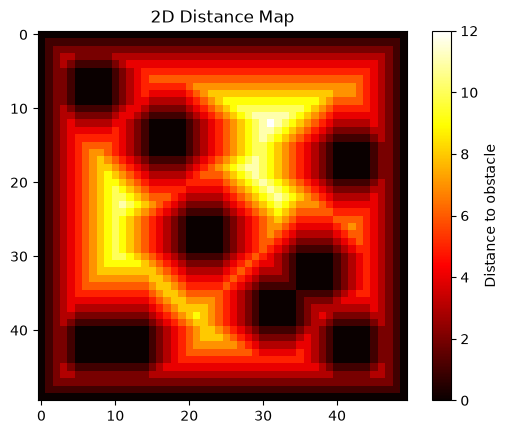

In [8]:
plt.imshow(map, cmap ='hot')
plt.colorbar(label='Distance to obstacle')
plt.title('2D Distance Map')
plt.show()

In [ ]:
#The distance map will help our particle filter evaluate how likely each possible robot position is, given our sensor observation. 
#After resampling, particles that better explain the measurements are more likely to remain. This allows the filter to narrow down where the robot might be

In [13]:
particles = np.random.randint(50, size=(1000,2)) #Genearates randoms integers, creating 1000 particles with 2 coordinates, and storing in one NumPy array

print(particles.shape)
print(particles[:5])

(1000, 2)
[[ 4 27]
 [45 27]
 [39 17]
 [47 15]
 [12  2]]


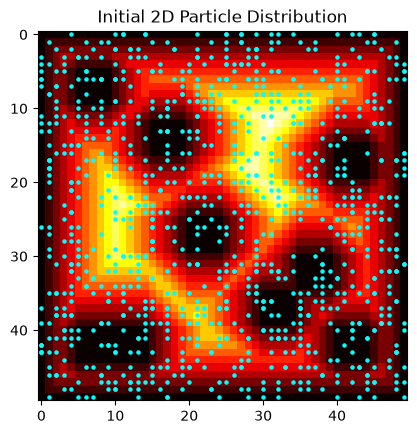

In [14]:
plt.imshow(map, cmap='hot')
plt.scatter(particles[:, 1], particles[:, 0], s=5, color='cyan') #Creating a scatter plot, where each dot represents 1 particle
plt.title('Initial 2D Particle Distribution')
plt.show()

In [15]:
#Need to introduce Gaussian noise

def predict_move_2d(particles, action, sigma=1):
    N = len(particles) #Inputs: 1000 possible robot locations (particles), our action cmd, 
    #std.dev of Gaussian motion noise. For simplicity, assume independednt motion errors
    #with the same std.dev in both directions

    noise = np.random.normal(0, sigma, size=(N, 2)) #x and y

    new_particles = particles + action + noise

    new_particles = np.clip(new_particles, 0, 49)

    return new_particles

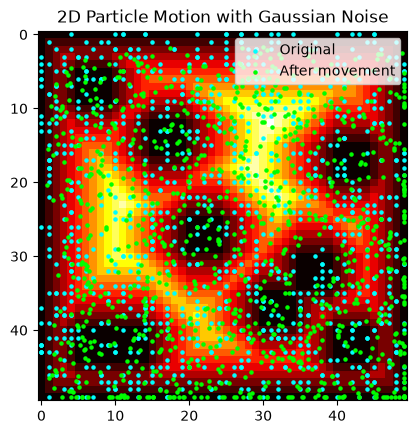

In [18]:
#Overlay both particle distributions on our distance map. Expect a high overlap because of the initial distribution variance
plt.imshow(map, cmap='hot')

plt.scatter(particles[:, 1], particles[:, 0],
            s=5, color='cyan', label='Original') #Original partciles

plt.scatter(moved_particles[:, 1], moved_particles[:, 0], #Predicted posterior position
            s=5, color='lime', label='After movement')

plt.legend()
plt.title('2D Particle Motion with Gaussian Noise')
plt.show()

In [19]:
def distance_ray(x, theta, map, max_range=4, step=0.1):
    n, m = map.shape
    ray_theta = x[2] + theta
    ray = np.array([np.cos(ray_theta), np.sin(ray_theta)])
    for d in np.linspace(0,max_range, int(max_range // step)):
      point = x[:2] + d * ray
      cell = (round(point[0]), round(point[1]))
      if cell[0] < 0 or cell[0] >= n or cell[1] < 0 or cell[1] >= m: #Simulating one range measurement by tracing a ray until it encounters an obstacle or has reached maximum range
        return d - step
      if map[cell[0], cell[1]] == 0:
        return d
    return max_range

def scan_map(x, map, max_range = 4.0, theta_res=0.2):
    theta_range = np.arange(-np.pi,np.pi,theta_res)
    dists = []
    for theta in theta_range:
      dist = distance_ray(x, theta, map, max_range=max_range) #Generating multiple range measurements around the robot
      dists.append(dist)
    dists = np.array(dists)
    return dists, theta_range

def ray_prob(point: np.ndarray, map:np.ndarray, std = 0.5): #How likely a measured ray endpoint is, based on its distance from an obstacle
    i, j = round(point[0]), round(point[1])
    n, m = map.shape
    out_of_bounds_dist = 0
    # Handle rays that go out of bounds
    if i < 0:
      i = 0
      out_of_bounds_dist += abs(i-point[0])
    elif i >= n:
      i = n-1
      out_of_bounds_dist += abs(i-point[0])
    if j < 0:
      j = 0
      out_of_bounds_dist += abs(j-point[1])
    elif j >= m:
      j = m-1
      out_of_bounds_dist += abs(j-point[1])

    dist = map[i, j] + out_of_bounds_dist
    return np.exp(-dist**2/(2*std**2))/np.sqrt(2*np.pi*std**2)

def likelihood_field_range_finder(z_dists, z_thetas, x, map, z_max = 4.0, std=0.5): #Combining the individual ray likelihoods into an overall potential robot position
  q = 1
  eps = 0.02
  n, m = map.shape
  for z, theta in zip(z_dists, z_thetas):
    if z > z_max - eps:
      continue
    ray_theta = x[2] + theta
    ray = np.array([np.cos(ray_theta), np.sin(ray_theta)])
    point = x[:2] + z * ray
    q *= ray_prob(point, map, std=std)
  return q
#Ignoring yaw, we keep theta =0


[ 9.52702703  9.72972973 10.33783784 11.55405405 13.68243243 15.
 15.         15.         15.          6.68918919  6.08108108  6.89189189
  8.20945946 15.         15.         14.69594595 15.         15.
 15.         15.         15.         15.         15.         15.
 15.         15.         15.         15.         12.26351351 10.74324324
  9.93243243  9.62837838]


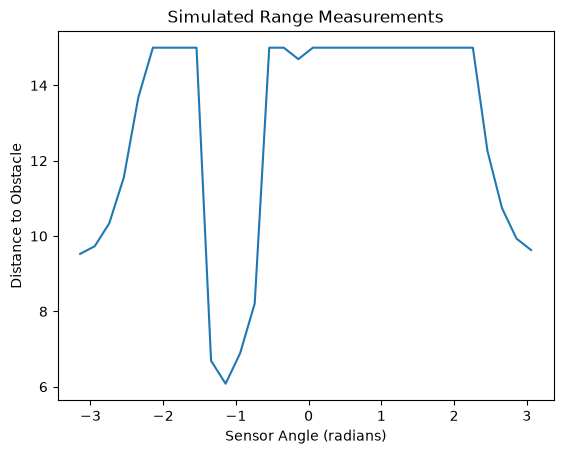

0.04237999106272858


In [22]:
robot = np.array([10, 25, 0])

z_dists, z_thetas = scan_map(robot, map, max_range=15)

print(z_dists)


plt.plot(z_thetas, z_dists)
plt.xlabel('Sensor Angle (radians)')
plt.ylabel('Distance to Obstacle')
plt.title('Simulated Range Measurements')
plt.show()

likelihood = likelihood_field_range_finder(
    z_dists, z_thetas, robot, map, z_max=15
)

print(likelihood)

In [23]:
##WHen originally plotting this, my resulting data was searching within a 4 grid cell range, and kept returning the 4 because it wasn't detecting any object.
#I plotted with an adjusted sensor range of 15 cells and it detected the obstacles at the different distances.

In [24]:
##We need to extend this calculation to every partcile and normalize their weights. We can then implement our resampling which is where the particles with higher weights wil become more common in our distribution.

In [26]:
position_A = np.array([10, 25, 0]) #Consider the simulated position that produded the observations
position_B = np.array([35, 10, 0]) # Different location

weight_A = likelihood_field_range_finder(
    z_dists, z_thetas, position_A, map, z_max=15 #Expecting pos.A to have a higher likelihood
)

weight_B = likelihood_field_range_finder(
    z_dists, z_thetas, position_B, map, z_max=15
)

print("Weight A:", weight_A)
print("Weight B:", weight_B)
print("Our likelihood model successfully gave pos. A ad higher likelihood than B. This is a measure of how well the observed sensor reading agrees with that candidate position")

Weight A: 0.04237999106272858
Weight B: 0.0
Our likelihood model successfully gave pos. A ad higher likelihood than B. This is a measure of how well the observed sensor reading agrees with that candidate position


In [27]:
weights = []

for particle in moved_particles: #loop through ALL partciles in our predicted distribution
    position = np.array([particle[0], particle[1], 0]) #Calling theta =0 per professors comment to ignore yaw

    weight = likelihood_field_range_finder(
        z_dists, z_thetas, position, map, z_max=15
    )

    weights.append(weight)

weights = np.array(weights)

print("Number of weights:", len(weights))
print("Nonzero weights:", np.count_nonzero(weights))
print("Maximum weight:", np.max(weights))
print("Total weight:", np.sum(weights))

Number of weights: 1000
Nonzero weights: 647
Maximum weight: 0.0007762166124127188
Total weight: 0.002330573973207411


In [ ]:
##normalize

In [ ]:
#resample

In [ ]:
#loop back

In [ ]:
#interactive widget